In [1]:
import numpy as np
import pandas as pd

from black_scholes import bsm_price
from hedging_engine import run_delta_hedging
from processes import simulate_gbm, simulate_merton_jump_diffusion
from metrics import summarize_pnl
from plots.PnL_plots import plot_pnl, plot_pnl_comparison

In [2]:
bsm_price(S=100, K=100, T=1, sigma=0.2, r=0.05)

np.float64(10.450583572185565)

In [3]:
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
N = 1008
REBALANCE_EVERY = 21

In [4]:
S = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=12)

In [5]:
seeds = [1, 5, 7, 42, 144, 44, 424, 34]

for s in seeds:
    S_seed = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=s)
    pnl_seed = run_delta_hedging(
        S=S_seed, K=K, T=T, sigma=sigma, r=r, rebalance_every=REBALANCE_EVERY
    )
    print(f"seed: {s}, mean p&l: {np.mean(pnl_seed)}, standard deviation of p&l: {np.std(pnl_seed)}")

seed: 1, mean p&l: 0.0061368768665002104, standard deviation of p&l: 0.9745902006253255
seed: 5, mean p&l: -9.481261801619638e-05, standard deviation of p&l: 0.967638651423855
seed: 7, mean p&l: -0.0032465320098115035, standard deviation of p&l: 0.9746946305960377
seed: 42, mean p&l: 0.010635641939823925, standard deviation of p&l: 0.9817954196871072
seed: 144, mean p&l: -0.0026945961760078854, standard deviation of p&l: 0.9696296303675747
seed: 44, mean p&l: -0.015481544318907836, standard deviation of p&l: 0.9902358234687015
seed: 424, mean p&l: -0.008251183303727679, standard deviation of p&l: 0.9780926455701827
seed: 34, mean p&l: 0.0009210648753087171, standard deviation of p&l: 0.962680303687042


In [6]:
pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r, rebalance_every=REBALANCE_EVERY)
summarize_pnl(pnl)

{'mean p&l': 0.01457741671119948,
 'std of p&l': 0.9826278247308209,
 'median of p&l': 0.019404078487974694,
 'skewness': -0.21150640461854403,
 'excess kurtosis': 1.7516077494325124,
 'VaR_95': -1.5876762034028464,
 'CVaR_95': -2.2594416083122923,
 'VaR_99': -2.6706729747361986,
 'CVaR_99': -3.361009837545856}

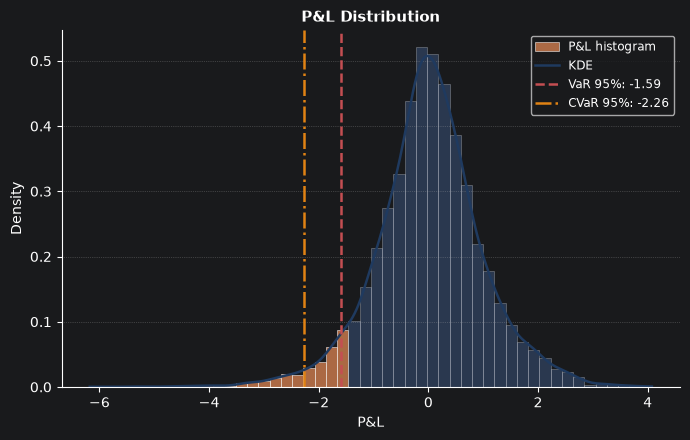

<Axes: title={'center': 'P&L Distribution'}, xlabel='P&L', ylabel='Density'>

In [7]:
plot_pnl(pnl)

In [8]:
params_common = dict(S0=100.0, mu=0.08, sigma=0.20, T=1.0, M=5000, N=252, seed=42)
hedge_params = dict(K=100.0, T=1.0, sigma=0.20, r=0.05)

paths = {
    "GBM": simulate_gbm(**params_common),
    "Merton (moderate)": simulate_merton_jump_diffusion(
        **params_common, lam=3.0, mu_j=-0.02, delta=0.05
    ),
    "Merton (stress)": simulate_merton_jump_diffusion(
        **params_common, lam=5.0, mu_j=-0.05, delta=0.10
    ),
}

In [9]:
pnl_by_regime = {
    name: run_delta_hedging(S=S_regime, **hedge_params)
    for name, S_regime in paths.items()
}

df_compare = pd.DataFrame(
    {name: summarize_pnl(pnl_regime) for name, pnl_regime in pnl_by_regime.items()}
).T

print(df_compare)

                   mean p&l  std of p&l  median of p&l  skewness  \
GBM                0.039284    1.901449       0.026974 -0.374820   
Merton (moderate) -0.772739    2.308646      -0.573471 -0.971489   
Merton (stress)   -4.614845    4.767910      -3.405802 -1.513576   

                   excess kurtosis     VaR_95    CVaR_95     VaR_99    CVaR_99  
GBM                       1.889581  -3.073940  -4.363435  -4.995352  -6.623841  
Merton (moderate)         3.037392  -4.886323  -6.884212  -8.121774  -9.894068  
Merton (stress)           3.527384 -14.017198 -18.121954 -20.747552 -24.768286  


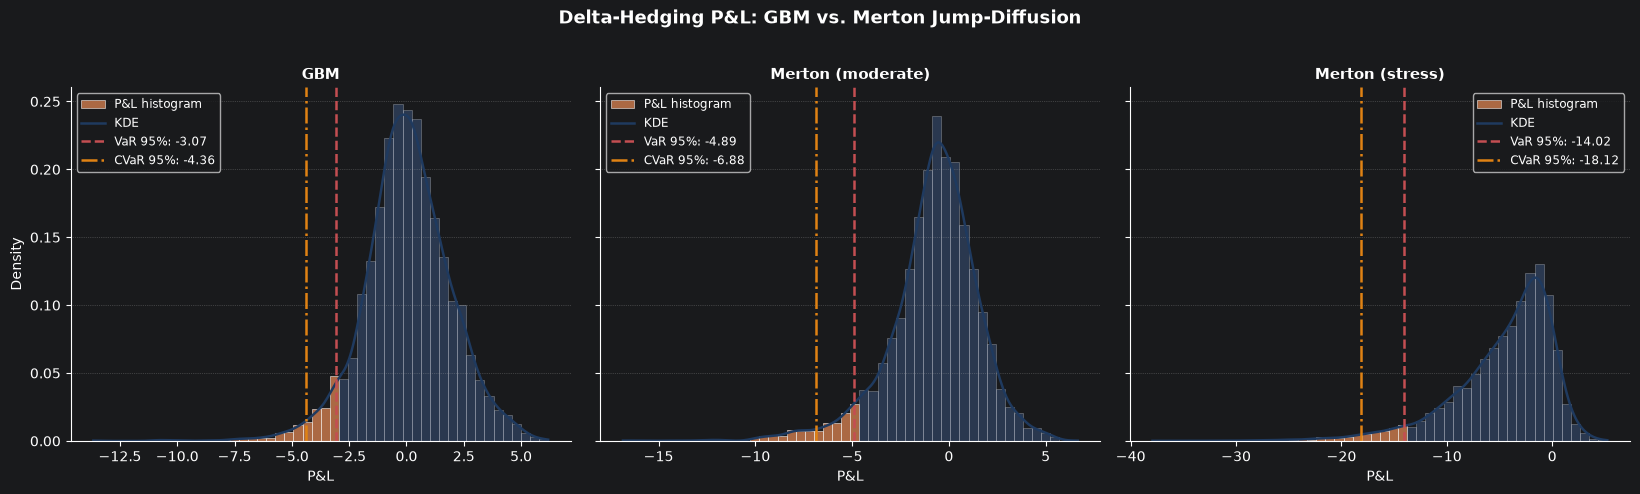

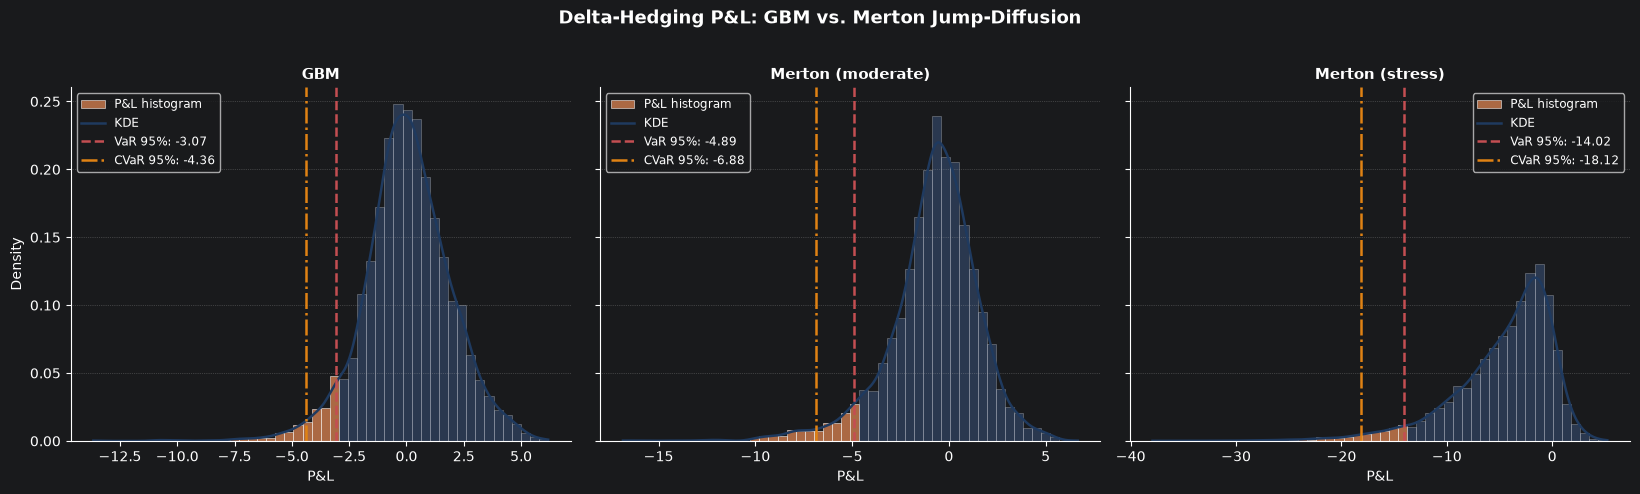

In [10]:
plot_pnl_comparison(pnl_by_regime)

In [11]:
# Compare 3 different hedging specifications:
# - monthly rebalance, no transactional cost
# - daily rebalance, no transactional cost
# - daily rebalance, transactional cost active

In [12]:
def compare_rebalance_and_costs(
    paths_dict: dict,
    hedge_base_params: dict,
    cost_bps: tuple = (1, 5, 10),
):
    configs = {
        "monthly_no_cost": {"rebalance_every": 21, "cost": 0.0},
        "daily_no_cost": {"rebalance_every": 1, "cost": 0.0},
    }
    for bps in cost_bps:
        configs[f"daily_{bps}bps"] = {"rebalance_every": 1, "cost": bps / 10_000}

    results = {}
    for cfg_name, cfg_params in configs.items():
        rows = {}
        for regime_name, S_regime in paths_dict.items():
            pnl_regime = run_delta_hedging(S=S_regime, **hedge_base_params, **cfg_params)
            rows[regime_name] = summarize_pnl(pnl_regime)
        results[cfg_name] = pd.DataFrame(rows).T

    df_summary = pd.concat(results, axis=1)
    diff_freq = results["daily_no_cost"] - results["monthly_no_cost"]
    diff_cost = pd.concat(
        {
            f"daily_{bps}bps": results[f"daily_{bps}bps"] - results["daily_no_cost"]
            for bps in cost_bps
        },
        axis=1,
    )

    return df_summary, diff_freq, diff_cost

In [13]:
df_costs, diff_freq, diff_cost = compare_rebalance_and_costs(
    paths_dict=paths,
    hedge_base_params=hedge_params,
    cost_bps=(1, 5, 10),
)

print("=== Every Specification ===")
print(df_costs)
print("\n=== The impact of change from rebalancing every 21 days to daily (no transactional costs) ===")
print(diff_freq)
print("\n=== The impact of transactional costs (daily rebalancing) ===")
print(diff_cost)

=== Every Specification ===
                  monthly_no_cost                                     \
                         mean p&l std of p&l median of p&l  skewness   
GBM                      0.039284   1.901449      0.026974 -0.374820   
Merton (moderate)       -0.772739   2.308646     -0.573471 -0.971489   
Merton (stress)         -4.614845   4.767910     -3.405802 -1.513576   

                                                                               \
                  excess kurtosis     VaR_95    CVaR_95     VaR_99    CVaR_99   
GBM                      1.889581  -3.073940  -4.363435  -4.995352  -6.623841   
Merton (moderate)        3.037392  -4.886323  -6.884212  -8.121774  -9.894068   
Merton (stress)          3.527384 -14.017198 -18.121954 -20.747552 -24.768286   

                  daily_no_cost  ... daily_5bps daily_10bps             \
                       mean p&l  ...    CVaR_99    mean p&l std of p&l   
GBM                    0.003474  ...  -1.980503   -0.6330

In [14]:
# Compare how volatility misspecification impacts the pnl

In [15]:
def compare_volatility(
    paths_dict: dict,
    hedge_base_params: dict,
    model_vol: float = 0.20,
    misspecified_vol: float = 0.30,
):
    base_params = {k: v for k, v in hedge_base_params.items() if k != "sigma"}

    configs = {
        "correct volatility": {"sigma": model_vol, "sigma_price": model_vol},
        "misspecified volatility": {"sigma": misspecified_vol, "sigma_price": model_vol},
    }

    results = {}
    for cfg_name, cfg_params in configs.items():
        rows = {}
        for regime_name, S_regime in paths_dict.items():
            pnl_regime = run_delta_hedging(S=S_regime, **base_params, **cfg_params)
            rows[regime_name] = summarize_pnl(pnl_regime)
        results[cfg_name] = pd.DataFrame(rows).T

    df_summary = pd.concat(results, axis=1)
    diff_misspecified = results["misspecified volatility"] - results["correct volatility"]

    return df_summary, diff_misspecified

In [16]:
df_vol, diff_vol = compare_volatility(
    paths_dict=paths,
    hedge_base_params=hedge_params,
    model_vol=0.20,
    misspecified_vol=0.30,
)

print("=== Every Specification ===")
print(df_vol)
print("\n=== The impact of misspecified volatility ===")
print(diff_vol)

=== Every Specification ===
                  correct volatility                                     \
                            mean p&l std of p&l median of p&l  skewness   
GBM                         0.039284   1.901449      0.026974 -0.374820   
Merton (moderate)          -0.772739   2.308646     -0.573471 -0.971489   
Merton (stress)            -4.614845   4.767910     -3.405802 -1.513576   

                                                                               \
                  excess kurtosis     VaR_95    CVaR_95     VaR_99    CVaR_99   
GBM                      1.889581  -3.073940  -4.363435  -4.995352  -6.623841   
Merton (moderate)        3.037392  -4.886323  -6.884212  -8.121774  -9.894068   
Merton (stress)          3.527384 -14.017198 -18.121954 -20.747552 -24.768286   

                  misspecified volatility                                     \
                                 mean p&l std of p&l median of p&l  skewness   
GBM                           